# 02 - learning curve and S

Trains the base model on 250k to 4.08M flows of week 18 (90/10 split, seed 0) and picks S = the smallest size within 0.5 macro-F1 points of the largest (S = 1M), saved in `config/params.json`.

Note: the first code cell (switching `label_encoder.json` to ranked order) uses `common`, which was imported in an earlier cell that is no longer here. If re-running, run the setup cell (the one that imports `common`) first. Paths point to our shared Drive folder.

In [3]:
import json, shutil
cfg = C.CONFIG_DIR
old = cfg / "label_encoder.json"

# keep the old alphabetical encoder as a backup in logs/
(C.PROJECT_ROOT / "logs").mkdir(exist_ok=True)
shutil.copy2(old, C.PROJECT_ROOT / "logs" / "label_encoder_A1_alphabetical_OLD.json")

ranked = C.load_classes()
new = {
    "note": "class id = position in classes.json classes_ranked. Replaces the A1 "
            "alphabetical encoding on Nov 3, before any model or sample was made.",
    "classes": ranked,
    "mapping": {c: i for i, c in enumerate(ranked)},
}
old.write_text(json.dumps(new, indent=2))
C.log_event("label_encoder.json switched from alphabetical (A1) to ranked order "
            "(common.py format); nothing trained before this. Backup in logs/.", who="Aya")
print(C.load_label_encoder())

{'google-ads': 0, 'office365': 1, 'google-www': 2, 'youtube': 3, 'tiktok': 4, 'snapchat': 5, 'teams': 6, 'microsoft-update': 7, 'facebook-graph': 8, 'spotify': 9}


In [4]:
import os, sys, time
from pathlib import Path
PROJECT = Path(r"G:\My Drive\CESNET_Project")
os.environ["CESNET_PROJECT"] = str(PROJECT)
sys.path.insert(0, str(PROJECT / "code"))

import psutil
import common as C

print("features:", len(C.FEATURES))
print("classes (ranked):", C.load_classes())
enc = C.load_label_encoder()
print("encoder:", enc)
print("lgb params:", C.lgb_params())

t0 = time.time()
df = C.load_week(18)
print(f"\nweek 18: {len(df):,} rows loaded in {time.time()-t0:.0f} s")

# compare with the counts checked in notebook 01
A1 = {"google-ads": 857263, "office365": 479580, "google-www": 442811, "youtube": 434689,
      "tiktok": 407311, "snapchat": 401705, "teams": 393552, "microsoft-update": 383336,
      "facebook-graph": 378526, "spotify": 353426}
inv = {v: k for k, v in enc.items()}
counts = df["y"].value_counts()
for i in range(10):
    name = inv[i]
    print(f"{i} {name:17s} {counts.get(i, 0):>9,}  A1={A1[name]:>9,}  {'OK' if counts.get(i, 0) == A1[name] else 'DIFFERENT'}")

print(f"\ndata in RAM: {df.memory_usage(deep=True).sum()/2**30:.2f} GB, "
      f"free RAM: {psutil.virtual_memory().available/2**30:.1f} GB")

features: 28
classes (ranked): ['google-ads', 'office365', 'google-www', 'youtube', 'tiktok', 'snapchat', 'teams', 'microsoft-update', 'facebook-graph', 'spotify']
encoder: {'google-ads': 0, 'office365': 1, 'google-www': 2, 'youtube': 3, 'tiktok': 4, 'snapchat': 5, 'teams': 6, 'microsoft-update': 7, 'facebook-graph': 8, 'spotify': 9}
lgb params: {'objective': 'multiclass', 'num_class': 10, 'learning_rate': 0.1, 'num_leaves': 64, 'min_data_in_leaf': 20, 'max_bin': 255, 'feature_fraction': 1.0, 'bagging_fraction': 1.0, 'lambda_l2': 0.0, 'deterministic': True, 'force_row_wise': True, 'num_threads': 4, 'verbosity': -1, 'seed': 42}

week 18: 4,532,199 rows loaded in 35 s
0 google-ads          857,263  A1=  857,263  OK
1 office365           479,580  A1=  479,580  OK
2 google-www          442,811  A1=  442,811  OK
3 youtube             434,689  A1=  434,689  OK
4 tiktok              407,311  A1=  407,311  OK
5 snapchat            401,705  A1=  401,705  OK
6 teams               393,552  A1=  3

In [5]:
import gc, time
import numpy as np, pandas as pd, lightgbm as lgb, psutil

# arrays for training, then free the DataFrame to save RAM
X, y = C.to_xy(df)
b = df["bytes_total"].to_numpy()
del df; gc.collect()

# fixed 90/10 split of week 18 (seed 0), saved for reproducibility
rng = np.random.default_rng(0)
perm = rng.permutation(len(y))
n_val = len(y) // 10
val_idx = np.sort(perm[:n_val])
train_perm = perm[n_val:]
C.SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
np.save(C.SAMPLES_DIR / "lc_w18_val_idx.npy", val_idx)
np.save(C.SAMPLES_DIR / "lc_w18_train_perm.npy", train_perm)
Xv, yv, bv = X[val_idx], y[val_idx], b[val_idx]
print(f"train pool {len(train_perm):,} flows, validation {len(val_idx):,} flows")

sizes = [250_000, 500_000, 1_000_000, 2_000_000, len(train_perm)]
out = C.RESULTS_DIR / "learning_curve.csv"
out.parent.mkdir(parents=True, exist_ok=True)
done = set(pd.read_csv(out)["train_rows"]) if out.exists() else set()

for n in sizes:
    if n in done:
        print(f"{n:>9,}: already done, skipping"); continue
    free = psutil.virtual_memory().available / 2**30
    if free < 3:
        print(f"STOP: only {free:.1f} GB free RAM. Close programs and re-run this cell."); break
    idx = np.sort(train_perm[:n])
    with C.Measure() as m:
        ds = lgb.Dataset(X[idx], label=y[idx])
        booster = lgb.train(C.lgb_params(), ds, num_boost_round=C.rounds()["base"])
    pred = C.predict_classes(booster, Xv)
    s, per_class, _ = C.evaluate(yv, pred, bv)
    row = {"train_rows": n, "val_rows": len(yv), "macro_f1": s["macro_f1"],
           "accuracy": s["accuracy"], "byte_err": s["byte_err"],
           "train_time_s": round(m.seconds, 1), "peak_mem_mb": round(m.peak_mb),
           "free_ram_gb_before": round(free, 1), "machine": C.platform.node()}
    pd.DataFrame([row]).to_csv(out, mode="a", header=not out.exists(), index=False)
    per_class.assign(train_rows=n).to_csv(C.RESULTS_DIR / "learning_curve_per_class.csv",
        mode="a", header=not (C.RESULTS_DIR / "learning_curve_per_class.csv").exists(), index=False)
    print(f"{n:>9,} flows: macro-F1 {s['macro_f1']:.4f}  acc {s['accuracy']:.4f}  "
          f"{m.seconds/60:.1f} min  peak {m.peak_mb/1024:.1f} GB")
    del ds, booster; gc.collect()

print("\n", pd.read_csv(out).to_string(index=False))

train pool 4,078,980 flows, validation 453,219 flows
  250,000 flows: macro-F1 0.8330  acc 0.8270  0.2 min  peak 2.0 GB
  500,000 flows: macro-F1 0.8370  acc 0.8308  0.4 min  peak 2.1 GB
1,000,000 flows: macro-F1 0.8399  acc 0.8337  0.8 min  peak 2.2 GB
2,000,000 flows: macro-F1 0.8417  acc 0.8355  1.5 min  peak 2.4 GB
4,078,980 flows: macro-F1 0.8424  acc 0.8363  2.9 min  peak 2.9 GB

  train_rows  val_rows  macro_f1  accuracy  byte_err  train_time_s  peak_mem_mb  free_ram_gb_before machine
     250000    453219  0.833013  0.827000  0.249474          12.1         2043                 4.5     Aya
     500000    453219  0.836975  0.830810  0.248526          24.0         2112                 4.6     Aya
    1000000    453219  0.839876  0.833749  0.244829          48.5         2225                 4.7     Aya
    2000000    453219  0.841671  0.835475  0.244301          88.9         2451                 4.4     Aya
    4078980    453219  0.842399  0.836326  0.238806         175.3         2

largest-size macro-F1 0.8424, cut-off 0.8374 -> S = 1,000,000


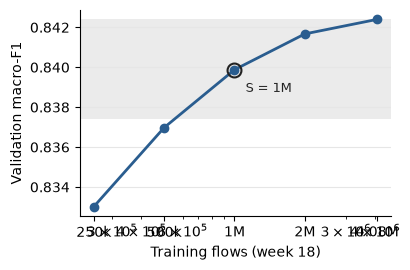

1000000


In [6]:
import matplotlib.pyplot as plt

lc = pd.read_csv(out).sort_values("train_rows").reset_index(drop=True)
largest = lc["macro_f1"].iloc[-1]
cutoff = largest - 0.005
S = int(lc.loc[lc["macro_f1"] >= cutoff, "train_rows"].min())
print(f"largest-size macro-F1 {largest:.4f}, cut-off {cutoff:.4f} -> S = {S:,}")

# write S to params.json (frozen from now on)
p = C.load_json("params.json")
assert p.get("S") in (None, S), f"params.json already has S={p.get('S')}"
p["S"] = S
p["S_rule"] = ("smallest training size whose validation macro-F1 is within 0.005 of the "
               "largest size; week 18, 90/10 split seed 0 (results/learning_curve.csv)")
C.save_json("params.json", p)
C.log_event(f"A2 learning curve done; S = {S:,} (rule: within 0.5 pt of largest, "
            f"{largest:.4f}). Written to config/params.json.", who="Aya")

# figure for the paper
fig, ax = plt.subplots(figsize=(4.2, 2.8))
ax.axhspan(cutoff, largest, color="#d9d9d9", alpha=0.5, lw=0)
ax.plot(lc["train_rows"], lc["macro_f1"], color="#2a5d8f", lw=2, marker="o", ms=6)
sel = lc[lc["train_rows"] == S].iloc[0]
ax.plot(S, sel["macro_f1"], marker="o", ms=10, mfc="none", mec="#222222", mew=1.5)
ax.annotate(f"S = {S/1e6:.0f}M", (S, sel["macro_f1"]), xytext=(8, -16),
            textcoords="offset points", fontsize=9, color="#222222")
ax.set_xscale("log")
ax.set_xticks(lc["train_rows"])
ax.set_xticklabels(["250k", "500k", "1M", "2M", "4.08M"])
ax.set_xlabel("Training flows (week 18)")
ax.set_ylabel("Validation macro-F1")
ax.grid(axis="y", color="#e6e6e6", lw=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
figdir = C.PROJECT_ROOT / "figures"; figdir.mkdir(exist_ok=True)
fig.savefig(figdir / "learning_curve.png", dpi=300)
fig.savefig(figdir / "learning_curve.pdf")
plt.show()
print(C.load_json("params.json")["S"])

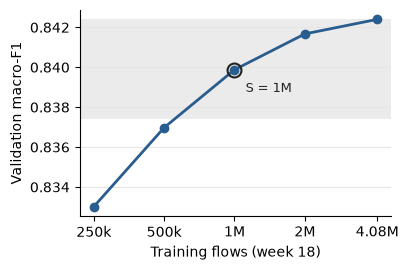

In [7]:
from matplotlib.ticker import NullLocator
ax.xaxis.set_minor_locator(NullLocator())   # remove the automatic in-between ticks
fig.savefig(figdir / "learning_curve.png", dpi=300)
fig.savefig(figdir / "learning_curve.pdf")
fig